# Combining datasets: `concat` and `merge`

**Lecture 10 · Wednesday, 18 November 2026 · Notebook 3 of 3 (Video 10C)**

Interesting questions often need data from **several tables**. Do municipalities with high employment also have high incomes? The employment rate (table RAS200) and disposable income (table INDKP101) come from different tables with different years. We combine them.

**Table of contents**<a id='toc0_'></a>
- 1. [Stacking rows: `concat`](#toc1_)
- 2. [Matching rows: `merge`](#toc2_)
- 3. [Which rows were lost? `indicator=True`](#toc3_)
- 4. [One row per municipality: many-to-one](#toc4_)
- 5. [Employment and income](#toc5_)
- 6. [Summary](#toc6_)

<a id='video-10c'></a>
> **Start Video 10C**  
> Question: do municipalities with more people in work also have higher incomes?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

emp = pd.read_csv('data/RAS200.csv')        # employment and participation rates, percent
inc = pd.read_csv('data/INDKP101.csv')      # average disposable income, DKK per person
area = pd.read_csv('data/ARE207.csv')       # area in km2

for name, data in [('emp', emp), ('inc', inc), ('area', area)]:
    print(f'{name:5s}: shape {data.shape}, columns {data.columns.to_list()}')

emp  : shape (1584, 4), columns ['municipality', 'year', 'emp_rate', 'part_rate']
inc  : shape (3626, 3), columns ['municipality', 'year', 'inc']
area : shape (99, 2), columns ['municipality', 'area_2008']


In [2]:
print('Years in emp:', emp['year'].min(), '-', emp['year'].max(), '|', emp['municipality'].nunique(), 'municipalities')
print('Years in inc:', inc['year'].min(), '-', inc['year'].max(), '|', inc['municipality'].nunique(), 'municipalities')

Years in emp: 2008 - 2023 | 99 municipalities
Years in inc: 1987 - 2023 | 98 municipalities


## 1. <a id='toc1_'></a>[Stacking rows: `concat`](#toc0_)

`pd.concat([a, b])` puts tables with the **same columns** on top of each other, for example two parts of the same data downloaded separately.

In [3]:
early = emp.loc[emp['year'] <= 2015]
late = emp.loc[emp['year'] > 2015]
both = pd.concat([early, late])
print(early.shape, '+', late.shape, '->', both.shape)

(792, 4) + (792, 4) -> (1584, 4)


## 2. <a id='toc2_'></a>[Matching rows: `merge`](#toc0_)

`pd.merge(left, right, on=keys, how=...)` puts **different columns** side by side, matching rows by the **keys**. Here a row is identified by municipality **and** year.

`how` decides what happens to rows without a partner:

| `how` | keeps |
| --- | --- |
| `'inner'` | only rows found in both tables |
| `'left'` | all rows of the left table |
| `'outer'` | all rows of both tables |

**Pause and predict:** `emp` has 1,584 rows and `inc` 3,626. Which of the three merges has the most rows?

In [4]:
for how in ['inner', 'left', 'outer']:
    merged = pd.merge(emp, inc, on=['municipality', 'year'], how=how)
    print(f'{how:6s}: {merged.shape[0]:5d} rows')

inner :  1568 rows
left  :  1584 rows
outer :  3642 rows


### Check that nothing was duplicated

If a key appeared twice in one table, `merge` would silently create duplicate rows. `validate='1:1'` checks that every key appears at most once on each side, and raises an error otherwise:

In [5]:
merged = pd.merge(emp, inc, on=['municipality', 'year'], how='inner', validate='1:1')
merged.head()

,municipality,year,emp_rate,part_rate,inc
0,Aabenraa,2008,74.6,76.3,166290.0
1,Aabenraa,2009,71.6,75.2,167106.0
2,Aabenraa,2010,70.9,74.5,181280.0
3,Aabenraa,2011,70.2,74.0,184117.0
4,Aabenraa,2012,69.5,73.7,188090.0


## 3. <a id='toc3_'></a>[Which rows were lost? `indicator=True`](#toc0_)

The inner merge has **fewer** rows than `emp`. Which ones were dropped? `indicator=True` adds a column `_merge` that says where each row came from.

In [6]:
check = pd.merge(emp, inc, on=['municipality', 'year'], how='outer', indicator=True)
print(check['_merge'].value_counts())

_merge
right_only    2058
both          1568
left_only       16
Name: count, dtype: int64


In [7]:
I = check['_merge'] == 'left_only'
print('Only in emp:', check.loc[I, 'municipality'].unique().tolist())

I = check['_merge'] == 'right_only'
print('Only in inc: years', check.loc[I, 'year'].min(), '-', check.loc[I, 'year'].max())

Only in emp: ['Christiansø']
Only in inc: years 1987 - 2007


Two reasons: the income table starts in 1987, long before the employment table, and it has **no row for Christiansø**. Always check what a merge drops before you trust the result.

## 4. <a id='toc4_'></a>[One row per municipality: many-to-one](#toc0_)

The area table has one row per municipality, but our merged table has 16 rows per municipality. Merging on `municipality` alone copies the area to every year. This is a **many-to-one** merge, which we check with `validate='m:1'`.

In [8]:
merged = pd.merge(merged, area, on='municipality', how='left', validate='m:1')
merged.loc[merged['municipality'] == 'Copenhagen'].head(3)

,municipality,year,emp_rate,part_rate,inc,area_2008
176,Copenhagen,2008,72.5,75.4,167519.0,88.25
177,Copenhagen,2009,70.0,74.7,171951.0,88.25
178,Copenhagen,2010,69.7,74.5,184281.0,88.25


## 5. <a id='toc5_'></a>[Employment and income](#toc0_)

Now the question: in 2023, do municipalities with higher employment rates have higher incomes?

**Pause and predict:** positive, negative or no relation?

Correlation across 98 municipalities: 0.48


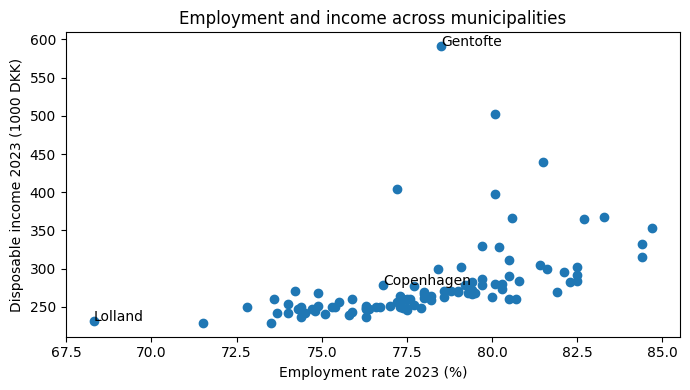

In [9]:
data_2023 = merged.loc[merged['year'] == 2023]

corr = data_2023[['emp_rate', 'inc']].corr().iloc[0, 1]
print(f'Correlation across {data_2023.shape[0]} municipalities: {corr:.2f}')

fig = plt.figure(figsize=(7, 4))
ax = fig.add_subplot(1, 1, 1)
ax.scatter(data_2023['emp_rate'], data_2023['inc']/1000)
for name in ['Gentofte', 'Copenhagen', 'Lolland']:
    row = data_2023.loc[data_2023['municipality'] == name]
    ax.annotate(name, (row['emp_rate'].iloc[0], row['inc'].iloc[0]/1000))
ax.set_xlabel('Employment rate 2023 (%)')
ax.set_ylabel('Disposable income 2023 (1000 DKK)')
ax.set_title('Employment and income across municipalities')
fig.tight_layout()
plt.show()

The relation is **positive** but far from perfect: Gentofte, north of Copenhagen, has much higher incomes than its employment rate alone would suggest. A correlation describes the data; it does not tell us what causes what.

## 6. <a id='toc6_'></a>[Summary](#toc0_)

| Goal | Code |
| --- | --- |
| stack tables with the same columns | `pd.concat([a, b])` |
| match rows by keys | `pd.merge(a, b, on=[...], how='inner' / 'left' / 'outer')` |
| guard against duplicates | `validate='1:1'` or `validate='m:1'` |
| see which rows were matched | `indicator=True` and `_merge` |

**Checklist for every merge:** count rows before and after, validate the keys, and look at what was dropped.

> **Stop Video 10C.** End of Lecture 10's recording sequence. In class we start the data project, which uses exactly these steps.